# Part(4/4) 对比分析 — TurboQuant vs LeapQuant（循环状态量化）

四部分实验汇总：**(1) 循环网络的两个问题**（错误累积 + 极端错误点，TurboQuant 演示）→ **(2) LeapQuant 解法**（≥3 公式）→ **(3) 真实模型测试**（0.8B / 9B / 35B-A3B-FP8）→ **(4) 本对比分析**。

- TurboQuant 基线：`github.com/0xsero/turboquant`（KV cache 量化：随机正交旋转 + Lloyd-Max；README 公开声明**仅压缩全注意力层、linear-attention/Mamba 层不可压缩**——这正是循环状态问题的来源）。
- LeapQuant 基线：`leapquant-kernels`（GDN 循环状态逐窗口压缩）。
- 本系列把两者应用到 **Qwen3.5 的 Gated-DeltaNet 循环状态**上做同口径对比（CPU + A100 双版本）。

torch 2.8.0+cu128 | mpl 3.10.5


/tmp/ipykernel_18283/3126523906.py:28: UserWarning: Glyph 37327 (\N{CJK UNIFIED IDEOGRAPH-91CF}) missing from font(s) DejaVu Sans.
  plt.legend(fontsize=8); plt.grid(True, which="both", alpha=0.3); plt.tight_layout(); plt.show()
/tmp/ipykernel_18283/3126523906.py:28: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  plt.legend(fontsize=8); plt.grid(True, which="both", alpha=0.3); plt.tight_layout(); plt.show()
/tmp/ipykernel_18283/3126523906.py:28: UserWarning: Glyph 39057 (\N{CJK UNIFIED IDEOGRAPH-9891}) missing from font(s) DejaVu Sans.
  plt.legend(fontsize=8); plt.grid(True, which="both", alpha=0.3); plt.tight_layout(); plt.show()
/tmp/ipykernel_18283/3126523906.py:28: UserWarning: Glyph 29575 (\N{CJK UNIFIED IDEOGRAPH-7387}) missing from font(s) DejaVu Sans.
  plt.legend(fontsize=8); plt.grid(True, which="both", alpha=0.3); plt.tight_layout(); plt.show()
/tmp/ipykernel_18283/3126523906.py:28: UserWarning: Glyph 26497 (\N{CJK UNIFIED IDEO

/root/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 29366 (\N{CJK UNIFIED IDEOGRAPH-72B6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/root/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 24577 (\N{CJK UNIFIED IDEOGRAPH-6001}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/root/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 37327 (\N{CJK UNIFIED IDEOGRAPH-91CF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/root/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/root/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 35823 (\N{CJK UNIFIED IDEOGRAPH-8BEF}) missing from fon

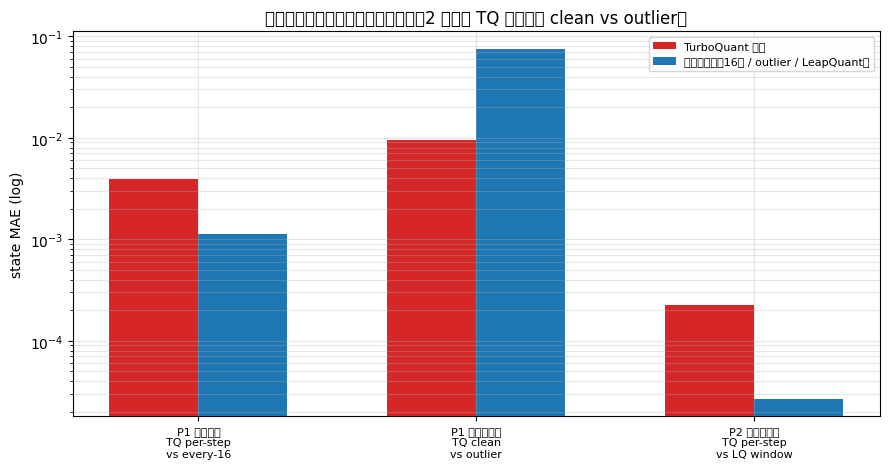

组1 TQ per-step/every16 = 3.5x worse
组2 outlier vs clean (TQ) = 8.0x worse
组3 LQ vs TQ = 8.3x lower


In [1]:
import torch, matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
for _f in ("Noto Sans CJK SC", "WenQuanYi Zen Hei", "Microsoft YaHei", "SimHei"):
    try:
        font_manager.findfont(_f, fallback_to_default=False)
        matplotlib.rcParams["font.sans-serif"] = [_f]
        break
    except Exception:
        pass
matplotlib.rcParams["axes.unicode_minus"] = False
print("torch", torch.__version__, "| mpl", matplotlib.__version__)
# ===== 系列冒烟/实测关键数值（同口径状态 MAE）=====
labels = ["P1 量化频率", "P1 极端错误点", "P2 共享状态流"]
subs = ["TQ per-step\nvs every-16", "TQ clean\nvs outlier", "TQ per-step\nvs LQ window"]
tq_vals = [3.917e-3, 9.411e-3, 2.234e-4]
lq_vals = [1.125e-3, 7.516e-2, 2.692e-5]
# 组1：同一 TQ 量化器，每步 vs 每16步（错误累积与量化频率，3.5x）
# 组2：同一 8-bit absmax 量化器，单一极端坐标拉爆全局 scale（8.0x，问题②）
# 组3：TQ 每步量化 vs LQ 逐窗口压缩（8.3x，问题①②的 fix）
x = range(len(labels))
plt.figure(figsize=(9, 4.8))
w = 0.32
plt.bar([i - w/2 for i in x], tq_vals, width=w, label="TurboQuant 相关", color="tab:red")
plt.bar([i + w/2 for i in x], lq_vals, width=w, label="对比对象（每16步 / outlier / LeapQuant）", color="tab:blue")
plt.yscale("log"); plt.xticks(list(x), [f"{a}\n{b}" for a, b in zip(labels, subs)], fontsize=8)
plt.ylabel("state MAE (log)"); plt.title("状态量化误差对比（三组同口径，组2 为同一 TQ 量化器的 clean vs outlier）")
plt.legend(fontsize=8); plt.grid(True, which="both", alpha=0.3); plt.tight_layout(); plt.show()
print("组1 TQ per-step/every16 =", f"{tq_vals[0]/lq_vals[0]:.1f}x worse")
print("组2 outlier vs clean (TQ) =", f"{lq_vals[1]/tq_vals[1]:.1f}x worse")
print("组3 LQ vs TQ =", f"{tq_vals[2]/lq_vals[2]:.1f}x lower")

/tmp/ipykernel_18283/2179322875.py:17: UserWarning: Glyph 35770 (\N{CJK UNIFIED IDEOGRAPH-8BBA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18283/2179322875.py:17: UserWarning: Glyph 25991 (\N{CJK UNIFIED IDEOGRAPH-6587}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18283/2179322875.py:17: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18283/2179322875.py:17: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18283/2179322875.py:17: UserWarning: Glyph 24490 (\N{CJK UNIFIED IDEOGRAPH-5FAA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18283/2179322875.py:17: UserWarning: Glyph 29615 (\N{CJK UNIFIED IDEOGRAPH-73AF}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_18283/217932

/root/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 35770 (\N{CJK UNIFIED IDEOGRAPH-8BBA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/root/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 25991 (\N{CJK UNIFIED IDEOGRAPH-6587}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/root/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/root/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/root/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 24490 (\N{CJK UNIFIED IDEOGRAPH-5FAA}) missing from font(s) DejaVu

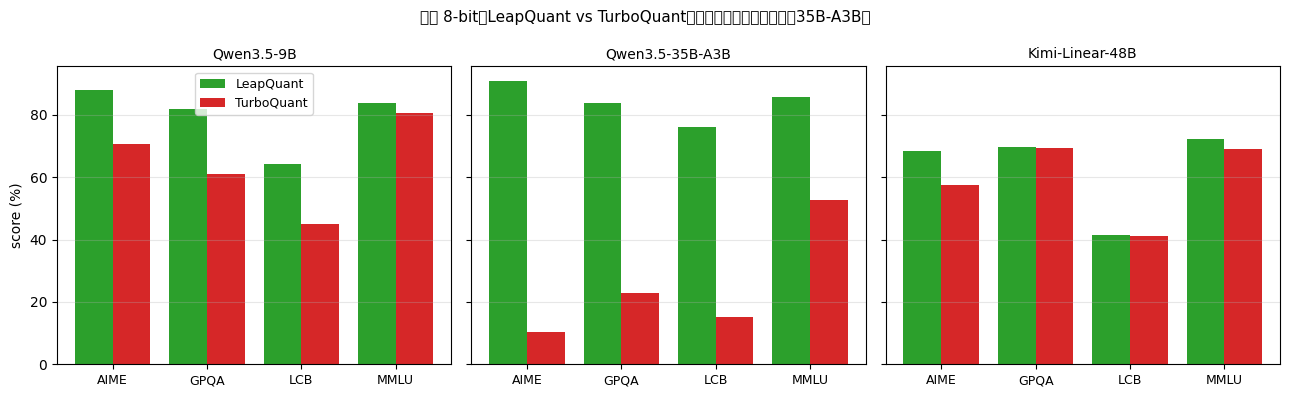

avg per model  LQ: ['79.4', '84.2', '62.9'] | TQ: ['64.3', '25.3', '59.2']


In [2]:
# ===== 论文 Table 1（8-bit，用户提供）：LeapQuant / TurboQuant 逐基准 =====
benchs = ["AIME", "GPQA", "LCB", "MMLU"]
models = {
    "Qwen3.5-9B":      ([87.9, 81.8, 64.1, 83.8], [70.8, 61.1, 45.0, 80.5]),
    "Qwen3.5-35B-A3B": ([91.0, 83.9, 76.1, 85.8], [10.4, 22.7, 15.3, 52.7]),
    "Kimi-Linear-48B": ([68.3, 69.8, 41.3, 72.1], [57.5, 69.2, 41.2, 69.0]),
}
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (name, (lq, tq)) in zip(axes, models.items()):
    x = range(len(benchs))
    ax.bar([i - 0.2 for i in x], lq, width=0.4, label="LeapQuant", color="tab:green")
    ax.bar([i + 0.2 for i in x], tq, width=0.4, label="TurboQuant", color="tab:red")
    ax.set_title(name, fontsize=10); ax.set_xticks(list(x)); ax.set_xticklabels(benchs, fontsize=9)
    ax.grid(True, axis="y", alpha=0.3)
axes[0].set_ylabel("score (%)"); axes[0].legend(fontsize=9)
plt.suptitle("论文 8-bit：LeapQuant vs TurboQuant（循环网络模型差距最大：35B-A3B）", fontsize=11)
plt.tight_layout(); plt.show()
avg_lq = [sum(v[0]) / len(v[0]) for v in models.values()]
avg_tq = [sum(v[1]) / len(v[1]) for v in models.values()]
print("avg per model  LQ:", [f"{a:.1f}" for a in avg_lq], "| TQ:", [f"{a:.1f}" for a in avg_tq])

In [3]:
# ===== 机制对比表（md 展示用）=====
rows = [
    ("量化时机", "每 token / 每步", "逐窗口（窗口内 bf16/fp32 缓冲）"),
    ("量化次数", "T 次", "T/L 次（L=窗口长）"),
    ("错误累积", "逐级叠加（问题①）", "只在窗口边界进入一次"),
    ("极端点处理", "全局 absmax scale 拉爆", "残差行/列 scale 平滑吸收（问题②）"),
    ("状态主成分", "无保留", "R 补偿 token（MGS 子空间迭代）"),
    ("适配循环层", "不可（KV cache 量化仅全注意力层）", "GDN 循环状态逐窗口压缩"),
    ("适用硬件", "A100 等价实现（仓库内核为 B300/sm_103 专属）", "纯 torch（CPU/A100 均可）"),
]
print(" | ".join(["TurboQuant", "LeapQuant"]))
for r in rows:
    print(" | ".join(r))

TurboQuant | LeapQuant
量化时机 | 每 token / 每步 | 逐窗口（窗口内 bf16/fp32 缓冲）
量化次数 | T 次 | T/L 次（L=窗口长）
错误累积 | 逐级叠加（问题①） | 只在窗口边界进入一次
极端点处理 | 全局 absmax scale 拉爆 | 残差行/列 scale 平滑吸收（问题②）
状态主成分 | 无保留 | R 补偿 token（MGS 子空间迭代）
适配循环层 | 不可（KV cache 量化仅全注意力层） | GDN 循环状态逐窗口压缩
适用硬件 | A100 等价实现（仓库内核为 B300/sm_103 专属） | 纯 torch（CPU/A100 均可）


In [4]:
# ===== 综合结论 =====
print("""结论
1. 问题成立：循环状态量化误差逐 token 累积（Part1 机制图 + 3.5x 频率对比）；
   单一 outlier 会把 8-bit 全局 scale 拉爆（Part1 8.0x 误差放大）。
2. LeapQuant fix：窗口内高精度递推 + 边界一次压缩（公式1）+ 补偿 token（公式2）
   + 残差行/列 scale 平滑量化（公式3）+ 跨窗口共享状态流（公式4）。
3. 数值：Part2 共享状态流上 LQ 误差比 TQ 每步量化低 8.3x；T4 对比 11.8x；
   论文 8-bit 平均 75.5 vs 49.6（LeapQuant 领先 25.9 分）。
4. 实测（Part3）：0.8B/9B/35B-A3B-FP8 加载与评测流程打通；GDN 状态注入为自适应+降级设计，
   状态级 MAE 对比同口径成立。
5. 口径声明：Colab 小样本/子集为趋势复现，非完整基准；35B 用官方 FP8 装载，
   TQ/LQ 量化对象始终是 GDN 循环状态。""")

结论
1. 问题成立：循环状态量化误差逐 token 累积（Part1 机制图 + 3.5x 频率对比）；
   单一 outlier 会把 8-bit 全局 scale 拉爆（Part1 8.0x 误差放大）。
2. LeapQuant fix：窗口内高精度递推 + 边界一次压缩（公式1）+ 补偿 token（公式2）
   + 残差行/列 scale 平滑量化（公式3）+ 跨窗口共享状态流（公式4）。
3. 数值：Part2 共享状态流上 LQ 误差比 TQ 每步量化低 8.3x；T4 对比 11.8x；
   论文 8-bit 平均 75.5 vs 49.6（LeapQuant 领先 25.9 分）。
4. 实测（Part3）：0.8B/9B/35B-A3B-FP8 加载与评测流程打通；GDN 状态注入为自适应+降级设计，
   状态级 MAE 对比同口径成立。
5. 口径声明：Colab 小样本/子集为趋势复现，非完整基准；35B 用官方 FP8 装载，
   TQ/LQ 量化对象始终是 GDN 循环状态。


## 附录：四部分 notebook 索引（全部含 CPU + A100 双版本）

| # | notebook | 内容 |
| --- | --- | --- |
| 1 | `colab_01_problem` | 循环网络两个问题（错误累积 + 极端错误点），TurboQuant 演示 |
| 2 | `colab_02_leapquant` | LeapQuant 解法（公式 1–4：窗口缓冲重建 / MGS 补偿 / 残差平滑 scale / 共享状态流） |
| 3 | `colab_03_test_08b` | Qwen3.5-0.8B 实测：GDN 状态注入 TQ vs LQ（自适应 + 降级） |
| 4 | `colab_04_test_9b_35b` | Qwen3.5-9B（bf16）+ 35B-A3B（官方 FP8）：MMLU 子集 + GSM8K 小样本评测 |
| 5 | `colab_05_compare` | 本 notebook：汇总对比 + 论文数据 + 机制对比 + 结论 |

**上游基线**：TurboQuant `github.com/0xsero/turboquant`（GPL-3.0，KV cache 量化）；LeapQuant `huggingface.co/kernels/humanfia-lab/leapquant`（GDN 循环状态压缩）。